# T020 · 分析分子动力学模拟

**说明：** 本教程属于 TeachOpenCADD 平台；该平台旨在教授领域专属技能，并提供可作为研究项目起点的流程模板。

**作者：**

- Mareike Leja，2020/21，Charité 的 [Volkamer Lab](https://volkamerlab.org/) 实习生
- David Schaller，2020/21，[Charité 的 Volkamer Lab](https://volkamerlab.org/)
- Andrea Volkamer，2021，[Charité 的 Volkamer Lab](https://volkamerlab.org/)

**中文版说明：** 本译本基于 TeachOpenCADD 上游仓库的固定版本 [commit 834b9ff59af69e8ba8d42aae23e92c15eb734ef0](https://github.com/volkamerlab/teachopencadd/commit/834b9ff59af69e8ba8d42aae23e92c15eb734ef0) 翻译整理；上游内容采用 [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) 许可。

## 本教程目标

本教程将介绍分子动力学（MD）模拟的分析方法，包括动画可视化、结构比对、RMSD 计算、指定原子间距离计算以及氢键分析。
请注意，我们将使用 **Talktorial T019** 生成的 EGFR 激酶（[PDB: 3POZ](https://www.rcsb.org/structure/3poz)）与抑制剂 [03P](https://www.rcsb.org/ligand/03P) 复合物的模拟结果（1 ns，100 帧）。

### *理论*部分内容

- MD 模拟
  - 在药物发现流程中的应用
  - 柔性结构与静态结构
- MD 模拟分析
  - 可视化
  - RMSD
  - 氢键分析

### *实践*部分内容

- 加载并可视化系统
- 结构比对
- 蛋白质与配体的 RMSD
  - 随时间变化的 RMSD
  - 帧间 RMSD
- 相互作用分析
  - 原子间距离
  - 氢键分析

### 参考文献

**理论背景：**

- 关于 MD 模拟对药物发现影响的综述（[_J Med Chem_ (2016), **59**(9), 4035‐4061](https://doi.org/10.1021/acs.jmedchem.5b01684)）
- 关于力场的综述（[_J Chem Inf Model_ (2018), **58**(3), 565-578](https://doi.org/10.1021/acs.jcim.8b00042)）
- 关于氢键的综述（[_PLoS One._ (2010), **5(8)**, e12029](https://doi.org/10.1371%2Fjournal.pone.0012029)）
- 分子相互作用指南（[_J. Med. Chem._ 2010, **53(14)**, 5061-84](https://doi.org/10.1021/jm100112j)）
- 关于[均方根偏差](https://en.wikipedia.org/wiki/Root-mean-square_deviation)的维基百科条目
- [MDAnalysis](https://www.mdanalysis.org/) 与 [NGL View](https://github.com/arose/nglview) 代码仓库

In [38]:
import sys

if "google.colab" in sys.modules:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 20
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt

## 理论

### MD 模拟

### 在药物发现流程中的应用

过去几十年来，人们对基于结构的药物设计越来越感兴趣。更快的算法以及采用 GPU 的计算架构推动了分子动力学（MD）模拟，使其逐渐成为药物发现流程中常规使用的计算工具之一。MD 模拟的一项主要优势，是能够更准确地估计药物与靶标的识别和结合过程。如今，许多计算方法都以 MD 模拟为基础，为新药候选物的设计、筛选和优化提供工具，应对研发流程中的各种挑战（[_J Med Chem._ 2016, **59(9)**, 4035-61](https://doi.org/10.1021/acs.jmedchem.5b01684)）。

关于如何对蛋白质-配体复合物执行 MD 模拟，请参阅 **Talktorial T019**。

### 柔性结构与静态结构

蛋白质-配体复合物的静态模型（例如 X 射线晶体结构）有助于评估先导化合物的结合模式，并据此系统性地提出新类似物的合成方案，以改善亲和力和理化性质。不过，静态结构无法解释药物与靶标结合的所有现象，因为配体、靶标及其周围环境（例如溶剂和/或膜）之间存在大量相互作用，仅凭系统当前平衡态的焓无法完整描述这些相互作用。

相比之下，基于力场的 MD 模拟能够考虑蛋白质和配体的结构柔性，以及药物结合过程中的熵贡献。因此，MD 模拟可以更准确地估计结合亲和力、检测构象变化、分析相互作用几何随时间的变化等（[_J Med Chem._ 2016, **59(9)**, 4035-61](https://doi.org/10.1021/acs.jmedchem.5b01684)）。

### 分析 MD 模拟

本教程旨在介绍 MD 模拟分析，因此我们会执行一些基础分析步骤，初步了解这一领域。

标准 MD 模拟结果通常保存在两类文件中：
* *系统拓扑*：描述模拟系统，即由确定的一组原子及其键连接关系构成的系统。
* *原子位置*：记录原子随时间变化的位置。

将这两类文件加载到分子可视化工具中，即可构建模拟系统。在下面使用的 MD 分析库（<code>MDAnalysis</code>）中，这个系统称为 *universe*。

#### 可视化

包含 MD 模拟的 universe 可以整体进行可视化，通常也可以制作动画。通过动画，可以直观观察构象变化、波动以及结合/解离过程。

![Model](./images/model.gif)

图 1：腺苷酸激酶（AdK）示例 MD 模拟的可视化，取自 [NGL View 示例](https://github.com/arose/nglview/blob/master/examples/mdanalysis.md)。

#### RMSD

追踪构象变化的一种更精细的方法是计算均方根偏差（RMSD，[维基百科](https://en.wikipedia.org/wiki/Root-mean-square_deviation_of_atomic_positions)）。该方法衡量一组原子坐标相对于参考坐标的偏离程度。RMSD 曲线可用于展示蛋白质整体或结构域在折叠或药物结合过程中的相对运动。RMSD 还可以用于将计算得到的对接构象与已知（例如晶体学测得的）结合姿势进行比较，从而验证对接流程 **（!注：需为对接教程添加恰当的参考文献！）**。

对于两组通常经过叠合的原子坐标 v 和 w（各含 n 个坐标），RMSD 定义如下：

$$RMSD(v,w) = \sqrt{ \frac{1}{n} \sum_{i=1}^n \|v_i - w_i\|² }$$

若要区分模拟中蛋白质的柔性部分和稳定部分，可以改用均方根涨落（RMSF）计算，以显示各残基相对于其平均结构的波动。

#### 氢键分析

氢键等非共价相互作用是形成配体-蛋白质复合物的关键因素（[_PLoS One._ (2010), **5(8)**, e12029](https://doi.org/10.1371%2Fjournal.pone.0012029)，[_J. Med. Chem._ 2010, **53(14)**, 5061-84](https://doi.org/10.1021/jm100112j)）。氢键的吸引作用源于部分带正电的氢原子指向部分带负电的氢键受体原子，例如氧或氮。分析氢键有助于了解配体-蛋白质复合物的稳定性，并为改造先导分子、提升活性提供线索。氢键强度可通过供体、氢原子和受体原子之间的距离及角度来估计。距离较短且键角接近 180° 通常表示氢键较强；距离较长、角度较小则表示氢键较弱（图 2）。

![H-Bonds](./images/CADD_Hbonds.png)  
图 2：供体（红色）和受体（蓝色）氧原子之间氢键的示例，箭头表示不同的键角和距离。由 *Mareike Leja, CADD Seminar 2020* 制作。

在计算分析中，通常使用几何阈值判断某种相互作用是否属于氢键：受体与氢原子之间的距离必须小于或等于距离阈值，供体-氢-受体夹角必须大于或等于角度阈值。例如，我们将用于分析的 Python 软件包 __[MDAnalysis](https://docs.mdanalysis.org/2.0.0/documentation_pages/analysis/hydrogenbonds.html)__ 默认最大距离为 3 Å、最小角度为 120°。

## 实践

接下来，我们将加载一段 MD 模拟，并分析配体和蛋白质随时间的变化。

所分析的模拟来自 **Talktorial T019**：模拟表皮生长因子受体（EGFR）激酶（[PDB:3POZ](https://www.rcsb.org/structure/3poz)）与抑制剂 [03P](https://www.rcsb.org/ligand/03P) 形成的复合物。系统总共模拟了 100 ps，并保存了 100 个快照（帧）（为方便使用，相关文件已放在本教程的 <code>data</code> 文件夹中）。

我们将先可视化模拟，再计算 RMSD 并分析氢键等相互作用。

In [39]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nglview as nv
import MDAnalysis as mda
from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA

In [40]:
HERE = Path(_dh[-1])
DATA = HERE / "data"

### 加载并可视化系统

首先，我们加载拓扑（<code>.pdb</code>）和轨迹（<code>.xtc</code>）文件，创建代表模拟系统的 MDAnalysis <code>universe</code>。
我们可以轻松地对整个 universe 进行可视化，包括播放轨迹动画。

[NGL Viewer](http://nglviewer.org/) 提供了预先构建的函数，可视化由 MD Analysis 等常用程序库加载的模拟。

In [41]:
md_universe = mda.Universe(str(DATA / "topology.pdb"), str(DATA / "trajectory.xtc"))
view = nv.show_mdanalysis(md_universe)
view

NGLWidget(max_frame=99)

In [42]:
view.render_image(trim=True, factor=2, transparent=True);

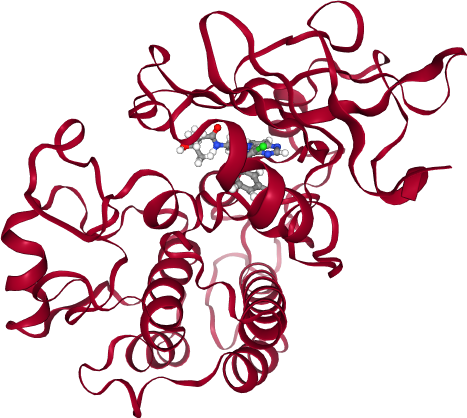

In [72]:
view._display_image()

### 结构比对

在这段较短轨迹的可视化中，几乎看不出这一点；但根据所用模拟软件包和设置，蛋白质在模拟过程中可能会旋转和平移。这会增加目视检查轨迹的难度，因此通常需要先进行结构比对，再开展分析。常见做法是将轨迹与蛋白质对齐。这样蛋白质不会偏离中心或发生整体旋转，便于观察配体解离或构象变化。

[MDAnalysis](https://docs.mdanalysis.org/stable/index.html) 框架支持通过字符串指定原子选择，并提供简单的内置选择关键字。例如，<code>protein</code> 会选择通常属于蛋白质的所有残基。

接下来，我们将轨迹中的结构（待对齐结构）叠合到参考结构上。参考结构当前激活的帧将作为比对参照。

In [44]:
# Set trajectory pointer to first frame as reference
md_universe.trajectory[0]

# in_memory=True is needed to actually modify the loaded trajectory
# if the trajectory is too big for memory, one can write out the aligned trajectory and reload it into a new universe
alignment = align.AlignTraj(
    mobile=md_universe, reference=md_universe, select="protein", in_memory=True
)
alignment.run()

In [45]:
view = nv.show_mdanalysis(md_universe)
view

NGLWidget(max_frame=99)

In [46]:
view.render_image(trim=True, factor=2, transparent=True);

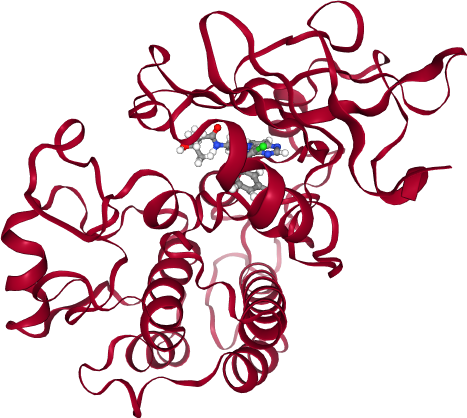

In [73]:
view._display_image()

### 蛋白质与配体的 RMSD

在动画中，蛋白质和配体很容易区分。不过，仅凭观察很难判断配体或蛋白质的位置/构象是否发生了显著变化。因此，我们将用更精细的方法——计算 RMSD——评估相对运动，并分别关注系统的不同部分（骨架、蛋白质整体和配体）。根据独特的残基名称可以方便地选择配体。本例中已知抑制剂的名称是 <code>03P</code>；也可以查看拓扑文件，或将光标悬停在上方动画中的配体原子上来查找名称。

In [48]:
ligand_name = "03P"

#### RMSD 随时间的变化

为了绘制 RMSD，我们编写一个函数：对 universe 中选定的原子组计算 RMSD，并返回 pandas <code>DataFrame</code>。

In [49]:
def rmsd_for_atomgroups(universe, selection1, selection2=None):
    """Calulate the RMSD for selected atom groups.

    Parameters
    ----------
    universe: MDAnalysis.core.universe.Universe
        MDAnalysis universe.
    selection1: str
        Selection string for main atom group, also used during alignment.
    selection2: list of str, optional
        Selection strings for additional atom groups.

    Returns
    -------
    rmsd_df: pandas.core.frame.DataFrame
        DataFrame containing RMSD of the selected atom groups over time.
    """

    universe.trajectory[0]
    ref = universe
    rmsd_analysis = rms.RMSD(universe, ref, select=selection1, groupselections=selection2)
    rmsd_analysis.run()
    columns = [selection1, *selection2] if selection2 else [selection1]
    rmsd_df = pd.DataFrame(np.round(rmsd_analysis.results.rmsd[:, 2:], 2), columns=columns)
    rmsd_df.index.name = "frame"
    return rmsd_df

运行该函数，计算模拟过程中以下对象的 RMSD：

* 蛋白质整体
* 蛋白质骨架原子
* 配体

计算时，会沿蛋白质骨架将分子叠合到第一帧（参考帧）。

In [50]:
rmsd = rmsd_for_atomgroups(md_universe, "backbone", ["protein", f"resname {ligand_name}"])
rmsd.head()

,backbone,protein,resname 03P
frame,,,
0,0.00,0.00,0.00
1,0.83,1.12,1.72
2,0.96,1.28,1.62
3,0.99,1.36,1.57
4,1.03,1.44,1.51


接下来绘制结果。

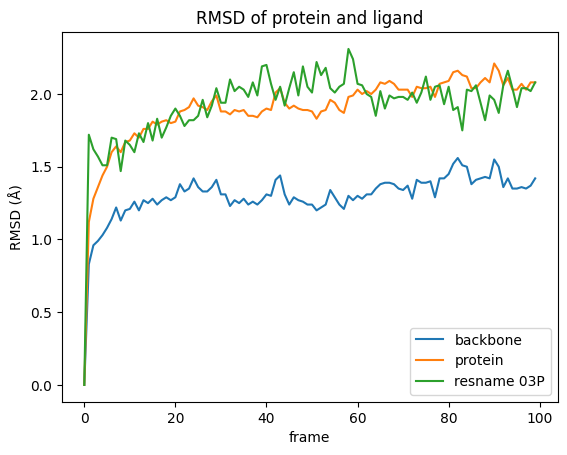

In [51]:
rmsd.plot(title="RMSD of protein and ligand")
plt.ylabel("RMSD (Å)");

从图中可以看出：

* 模拟过程中骨架只有轻微的构象变化，这并不意外，因为叠合时使用的是骨架。
* 将蛋白质侧链纳入 RMSD 计算后，测得的运动幅度会大于只考虑蛋白质骨架时的结果。
* 在本次模拟中，配体的运动幅度与蛋白质侧链相近。不过，情况并非总是如此：配体可能运动得更自由；除构象变化外，还可能发生方向性移动。如果配体 RMSD 特别高，这种整体移动可能是原因之一。

#### 帧间 RMSD

前面的图显示了每个时间点相对于初始状态的偏差。
现在，我们将计算所有帧两两之间的差异，并用热图显示。

In [52]:
def RMSD_dist_frames(universe, selection):
    """Calculate the RMSD between all frames in a matrix.

    Parameters
    ----------
    universe: MDAnalysis.core.universe.Universe
        MDAnalysis universe.
    selection: str
        Selection string for the atomgroup to be investigated, also used during alignment.

    Returns
    -------
    array: np.ndarray
        Numpy array of RMSD values.
    """
    pairwise_rmsd = diffusionmap.DistanceMatrix(universe, select=selection)
    pairwise_rmsd.run()
    return pairwise_rmsd.results.dist_matrix

首先，使用上面定义的函数计算蛋白质和配体的距离矩阵。
然后，将两者绘制为并排的热图。

In [53]:
dist_matrix_protein = RMSD_dist_frames(md_universe, "protein")
dist_matrix_ligand = RMSD_dist_frames(md_universe, f"resname {ligand_name}")

为了便于比较两张热图，需要将两张图的最小值和最大值设为相同。
我们将最小值设为 0，并根据距离矩阵确定上限。

In [54]:
# get maximal distance between all frames
max_dist = max(np.amax(dist_matrix_ligand), np.amax(dist_matrix_protein))

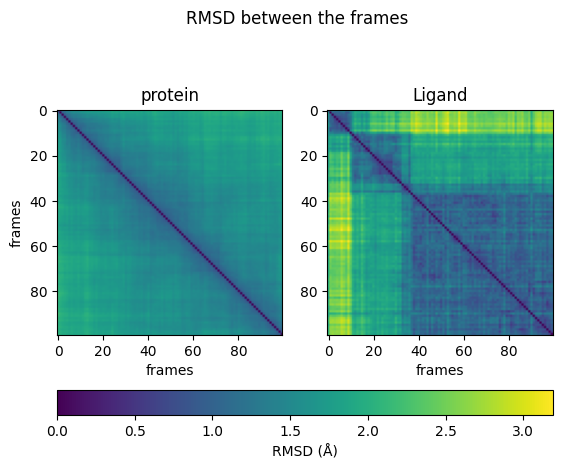

In [55]:
fig, ax = plt.subplots(1, 2)
fig.suptitle("RMSD between the frames")

# protein image
img1 = ax[0].imshow(dist_matrix_protein, cmap="viridis", vmin=0, vmax=max_dist)
ax[0].title.set_text("protein")
ax[0].set_xlabel("frames")
ax[0].set_ylabel("frames")

# ligand image
img2 = ax[1].imshow(dist_matrix_ligand, cmap="viridis", vmin=0, vmax=max_dist)
ax[1].title.set_text("Ligand")
ax[1].set_xlabel("frames")

fig.colorbar(img1, ax=ax, orientation="horizontal", fraction=0.1, label="RMSD (Å)");

从热图可以看出，蛋白质在不同状态之间持续、平稳地运动；配体则会在不同状态之间“跳转”，有时还会反复到达相似的构象。

### 相互作用分析

现在，我们来考察蛋白质与配体之间的相互作用。再次可视化系统，并显示结合口袋中的更多细节：展示配体周围 5 Å 范围内的所有残基，并显示原子和键。

In [56]:
# select pocket residues
pocket_resids = set(
    md_universe.select_atoms(f"(around 5 resname {ligand_name}) and protein").resids
)
view2 = nv.show_mdanalysis(md_universe)
view2.add_representation(
    "licorice", selection=f"protein and ({' '.join([str(x) for x in pocket_resids])})"
)
view2.center(selection="ligand")
view2

NGLWidget(max_frame=99)

In [57]:
view2.render_image(trim=True, factor=2, transparent=True);

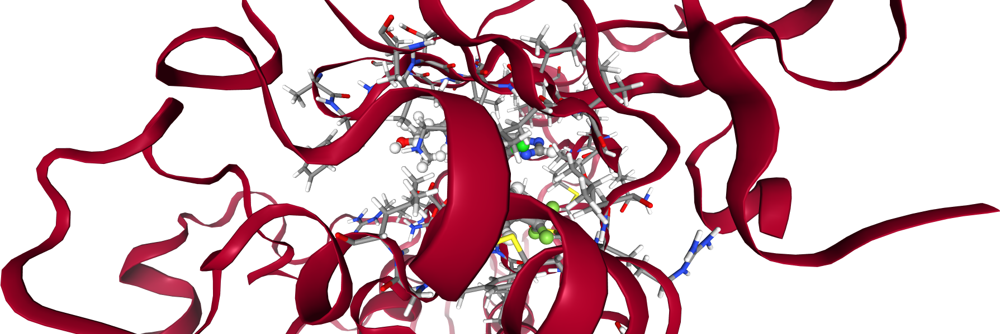

In [74]:
view2._display_image()

#### 原子间距离

现在放大结合口袋，寻找可能与研究问题相关的相互作用。本例中，我们关注甲硫氨酸 793 的主链氮原子与配体芳香环之间的近距离接触。理论上，只要两组原子的原子数相同，就可以计算两组原子之间的距离；但本例要计算的是两个单原子之间的距离。
通过组合残基编号及该残基内的原子名称，可以唯一指定单个原子。残基名称并不唯一，因此这里不使用残基名称。
将光标悬停在上方细节视图中选中的原子上，即可查看原子名称及其残基编号。

In [59]:
protein_residue_id = "793"
protein_atom_name = "N"
ligand_id = "1"
ligand_atom_name = "N4"

我们选择用于分析的原子组；本例中的每组只包含一个原子。

In [60]:
atomgroup_protein = md_universe.select_atoms(
    f"resid {protein_residue_id} and name {protein_atom_name}"
)
atomgroup_ligand = md_universe.select_atoms(f"resname {ligand_name} and name {ligand_atom_name}")

现在，可以使用 MDAnalysis 的 <code>dist</code> 函数计算 universe 当前帧中两个原子之间的距离。
该函数返回一个数组的数组：前两项是残基编号，我们只需读取第三项，即距离。

In [61]:
distance = dist(atomgroup_protein, atomgroup_ligand)
print(
    f"The distance between residues {protein_residue_id} and {ligand_id} is {distance[2][0]:.2f} Å"
)

The distance between residues 793 and 1 is 3.52 Å


该距离为 3.5 Å，足够近，可能参与介导配体结合，值得进一步考察。刚才测量的配体与甲硫氨酸 793 主链氮原子之间的相互作用，实际上是许多激酶中配体与铰链区形成的一种已知相互作用。

为进一步了解这一相互作用，我们想追踪距离随时间的变化。可以遍历各帧并逐帧计算距离。universe 的 trajectory 属性相当于一个指针，一次只保存一个时间步的信息。沿轨迹移动指针时，各原子选择会自动更新。

In [62]:
distances = []
for _ in md_universe.trajectory:
    distance = dist(atomgroup_protein, atomgroup_ligand)
    distances.append(distance[2][0])

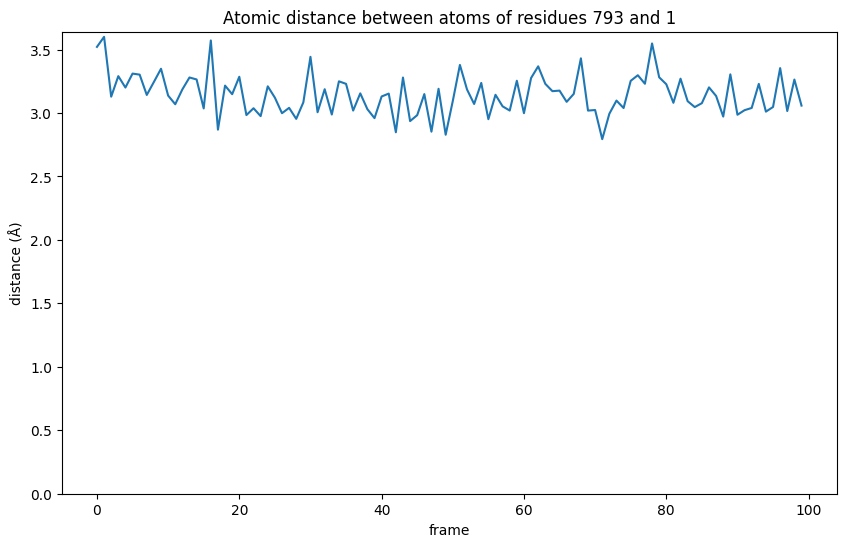

In [63]:
plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.gca().set_ylim(bottom=0)
plt.ylabel("distance (Å)")
plt.xlabel("frame")
plt.title(f"Atomic distance between atoms of residues {protein_residue_id} and {ligand_id}")
plt.show()

从图中可以看出，相互作用期间的距离比第一帧观察到的 3.52 Å 更短。这意味着相互作用起初增强；虽然存在波动，但在较长时段内保持相对稳定。

#### 氢键分析

我们分析的铰链区相互作用实际上形成了氢键。甲硫氨酸主链上的氮原子充当供体，配体芳香环上的氮原子充当受体。

回到可视化结果，查找形成氢键的氢原子名称。之后可以使用 [MDAnalysis](https://docs.mdanalysis.org/1.0.0/documentation_pages/analysis/hydrogenbonds.html) 的氢键分析功能，确定氢键的几何特征（距离和角度）。氢键分析会处理所有帧，不需要手动逐帧遍历，绘图也很方便。

In [64]:
hydrogen_name = "H"

In [65]:
def run_hydrogenbond_analysis(
    universe,
    donor_resid,
    donor_atom,
    hydrogen_atom,
    acceptor_resid,
    acceptor_atom,
    h_cutoff=1.2,
    a_cutoff=3.0,
    angle_cutoff=120,
):
    """
    Perform an hydrogen bond analysis between selcted atom groups.
    Return the data as readable, formatted data frame.

    Parameters
    ----------
    universe: MDAnalysis.core.universe.Universe
        MDAnalysis universe.
    donor_resid: str
        Residue Id of residue containing donor atom in MDAnalysis universe.
    donor_atom: str
        Name of the donor atom in the MDAnalysis universe.
    hydrogen_atom: str
        Name of involved hydrogen atom in the MDAnalysis universe.
    acceptor_resid: str
        Residue Id of residue containing acceptor atom in the MDAnalysis universe.
    acceptor_atom: str
        Name of the acceptor atom in the MDAnalysis universe.
    h_cutoff: float, optional
        Distance cutoff used for finding donor-hydrogen pairs.
    a_cutoff: float, optional
        Donor-acceptor distance cutoff for hydrogen bonds.
    angle_cutoff: int, optional
        D-H-A angle cutoff for hydrogen bonds.

    Returns
    -------
    bond : pandas.core.frame.DataFrame
        DataFrame containing hydrogen bond information over time.
    """

    # set up and run the hydrogen bond analysis (HBA)
    hbonds = HBA(
        universe=universe,
        donors_sel="resid " + donor_resid + " and name " + donor_atom,
        hydrogens_sel="resid " + donor_resid + " and name " + hydrogen_atom,
        acceptors_sel="resid " + acceptor_resid + " and name " + acceptor_atom,
        d_h_cutoff=h_cutoff,
        d_a_cutoff=a_cutoff,
        d_h_a_angle_cutoff=angle_cutoff,
    )
    hbonds.run()
    # extract bond data
    bond = pd.DataFrame(np.round(hbonds.results.hbonds, 2))
    # name columns (according to MDAnalysis function description)
    bond.columns = [
        "frame",
        "donor_index",
        "hydrogen_index",
        "acceptor_index",
        "distance",
        "angle",
    ]
    # set frame as the index
    bond["frame"] = bond["frame"].astype(int)
    bond.set_index("frame", inplace=True, drop=True)
    return bond

我们使用该函数执行氢键分析，并返回一个数据框。

In [66]:
bond = run_hydrogenbond_analysis(
    md_universe, protein_residue_id, protein_atom_name, hydrogen_name, ligand_id, ligand_atom_name
)
bond.head()

/opt/miniconda3/envs/T020_3120/lib/python3.12/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:747: UserWarning: No hydrogen bonds were found given d-a cutoff of 3.0 between Donor, resid 793 and name N, and Acceptor, resid 1 and name N4.
  warnings.warn(
/opt/miniconda3/envs/T020_3120/lib/python3.12/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:779: UserWarning: No hydrogen bonds were found given angle of 120 between Donor, resid 793 and name N, and Acceptor, resid 1 and name N4.
  warnings.warn(


,donor_index,hydrogen_index,acceptor_index,distance,angle
frame,,,,,
17,1483.0,1484.0,5529.0,2.87,144.73
21,1483.0,1484.0,5529.0,2.98,162.87
23,1483.0,1484.0,5529.0,2.98,173.41
26,1483.0,1484.0,5529.0,3.00,175.31
28,1483.0,1484.0,5529.0,2.95,163.73


在表格中可以看到，该氢键只在模拟的部分帧中被识别出来。

所用模块按照预先设定的严格条件查找氢键。使用默认设置时，只有当供体与受体之间的距离大于 3 Å、供体与氢原子之间的距离小于 1.2 Å，且键角大于 120° 时才会识别该氢键（见图 1）。不满足这些条件的帧不会被纳入结果。

若要追踪整个模拟过程中的氢键，可以调整阈值，以便识别氢键较“弱”的状态。
从上表看，角度似乎足够大，而距离接近 3 Å 的截断值。因此，我们将供体与受体之间的距离截断值提高到 5 Å，再次进行分析。

In [67]:
bond = run_hydrogenbond_analysis(
    md_universe,
    protein_residue_id,
    protein_atom_name,
    hydrogen_name,
    ligand_id,
    ligand_atom_name,
    a_cutoff=5.0,
)
bond.head()

,donor_index,hydrogen_index,acceptor_index,distance,angle
frame,,,,,
0,1483.0,1484.0,5529.0,3.52,166.39
1,1483.0,1484.0,5529.0,3.60,145.63
2,1483.0,1484.0,5529.0,3.13,173.95
3,1483.0,1484.0,5529.0,3.29,151.99
4,1483.0,1484.0,5529.0,3.20,170.21


接下来绘制氢键。

In [68]:
def plot_hydrogen_bond_over_time(bond):
    """
    Plot the distance and degree of a chosen hydrogen bond over time.
    Peaks in angle and dips in distance represent moments of strong binding.

    Parameters
    ----------
    bond: pandas.core.frame.DataFrame
        Hydrogen bond analysis data frame with named columns.
    """

    donor_index = bond.iloc[0].donor_index
    acceptor_index = bond.iloc[0].acceptor_index

    # add values for missing frames for gapless plotting
    bond = bond.reindex(np.arange(0, 99))

    # plot the data
    fig = plt.figure(figsize=(10, 6))
    distance = bond.distance.plot(
        title=f"H-Bond between donor {donor_index} and acceptor {acceptor_index}",
        style="o-",
        x="frame",
    )
    distance.set_ylabel("distance (Å)")
    distance.set_xlabel("frame")
    distance.set_ylim(bottom=0)
    angle = bond.angle.plot(secondary_y=True, style="o-", x="frame")
    angle.set_ylabel("angle (°)")
    angle.set_xlabel("frame")
    angle.set_ylim(bottom=0)
    fig.legend(loc="lower right", bbox_to_anchor=(1, 0), bbox_transform=distance.transAxes)
    plt.show()

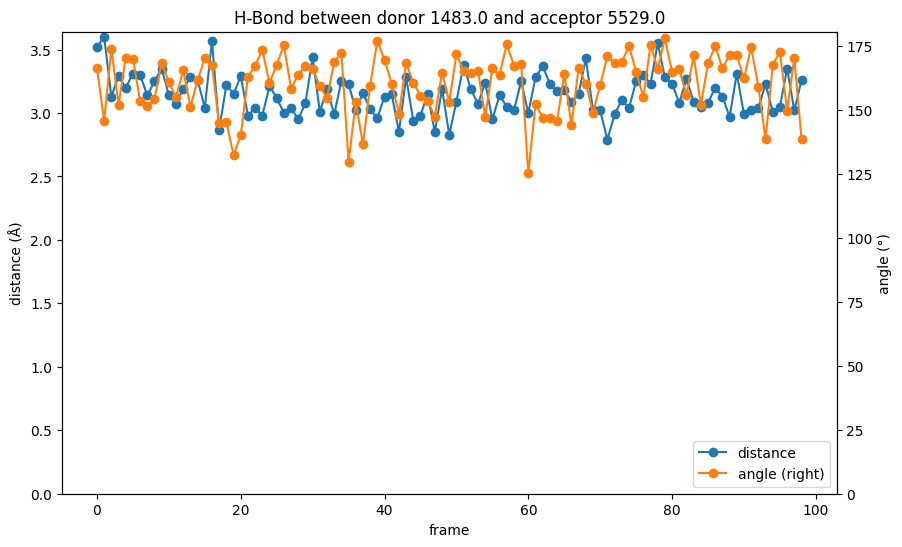

In [69]:
plot_hydrogen_bond_over_time(bond)

氢键分析中的距离值与前面单独绘制的距离曲线相同，但结合键角后能获得更多信息。前面提到，整个模拟过程中的距离都处于氢键长度的较大一端；但键角始终接近 180°，有助于稳定该氢键。根据这项分析，我们可以推测，激酶铰链区甲硫氨酸主链参与的相互作用确实是配体结合的重要因素。

In [70]:
view_strong = nv.show_mdanalysis(md_universe)
view_strong.add_representation("ball+stick", selection=f"protein and {protein_residue_id}")
view_strong.center(selection="ligand")
view_strong.frame = 71
view_strong

NGLWidget(frame=71, max_frame=99)

In [71]:
view_bad = nv.show_mdanalysis(md_universe)
view_bad.add_representation("ball+stick", selection=f"protein and {protein_residue_id}")
view_bad.center(selection="ligand")
view_bad.frame = 1
view_bad

NGLWidget(frame=1, max_frame=99)

## 讨论

分析 MD 模拟的方法有很多。本教程只介绍了其中一小部分，帮助读者初步了解这个领域。有些方法较为直接，例如系统可视化和 RMSD 计算；另一些则需要更多技巧。尤其是氢键分析，目前仍需要手动输入参数并调整阈值。不过，随着领域不断发展，我们可以期待相关分析框架日趋完善。

本次分析使用的 MD 轨迹过短，无法提供关于结合/解离事件甚至蛋白质或配体构象变化的统计学显著证据。要充分利用 MD 模拟的能力，需要使用高性能计算集群。[Folding@home](https://foldingathome.org/) 联盟通过整合世界各地计算机的算力来应对重要科学挑战，其网站展示了 MD 模拟带来的许多有趣发现。

## 测验

- 哪种氢键最强？
  - A：供体-受体距离 = 3.5 Å，供体-氢-受体夹角 = 180°
  - B：供体-受体距离 = 2.7 Å，供体-氢-受体夹角 = 170°
  - C：供体-受体距离 = 3.2 Å，供体-氢-受体夹角 = 150°
- 尝试将轨迹与配体对齐。这会如何影响 RMSD 曲线？
- 选择另一对原子并分析它们之间的相互作用。
- 你能否编写一个函数，计算蛋白质残基的均方根涨落（RMSF）？